# 📧 Task 4: Email Spam Detection with Machine Learning

**Objective:** Build a Natural Language Processing (NLP) binary classifier that distinguishes  
**spam** messages from legitimate (**ham**) messages.

**Tech Stack:** Python · pandas · scikit-learn (TF-IDF, Naive Bayes/SVM) · NLTK · WordCloud

---

### 📋 Table of Contents
1. Import Libraries & Load Data
2. Data Exploration & Class Distribution
3. Text Preprocessing Pipeline
4. TF-IDF Feature Extraction
5. Model Training & Evaluation
6. Discussion: Why Recall Matters in Spam Detection
7. **Bonus:** WordCloud Visualisations
8. Best Model Declaration

---

## 1. 📦 Import Libraries & Load Dataset

In [1]:
# === Core Libraries ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import re
import string

# === NLP Libraries ===
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
import nltk

# === scikit-learn Modules ===
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

# === WordCloud ===
from wordcloud import WordCloud

# === Configuration ===
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 120
plt.rcParams['font.family'] = 'sans-serif'

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [2]:
# --- Load the SMS Spam dataset ---
df = pd.read_csv('datasets/spam.csv')
print(f"📊 Dataset loaded: {df.shape[0]} rows × {df.shape[1]} columns")
df.head(10)

📊 Dataset loaded: 5574 rows × 2 columns


,type,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


## 2. 🔍 Data Exploration & Class Distribution

In [3]:
# --- Rename columns for clarity ---
df.columns = ['label', 'message']
print(f"📐 Shape: {df.shape}")
print(f"\n📋 Data Types:\n{df.dtypes}")

📐 Shape: (5574, 2)

📋 Data Types:
label      str
message    str
dtype: object


In [4]:
# --- Null value check ---
print("\n🔎 Missing Values:\n")
print(df.isnull().sum())


🔎 Missing Values:

label      0
message    0
dtype: int64


In [5]:
# --- Check for duplicates ---
dupes = df.duplicated().sum()
print(f"\n🔄 Duplicate messages: {dupes}")
if dupes > 0:
    df.drop_duplicates(inplace=True)
    print(f"✅ Removed duplicates. New shape: {df.shape}")


🔄 Duplicate messages: 414


✅ Removed duplicates. New shape: (5160, 2)


In [6]:
# --- Class Distribution ---
class_dist = df['label'].value_counts()
class_pct = df['label'].value_counts(normalize=True) * 100

print("\n🏷️ Class Distribution:\n")
for label, count in class_dist.items():
    print(f"  {label.upper():5s} → {count:5d} messages ({class_pct[label]:.1f}%)")


🏷️ Class Distribution:

  HAM   →  4518 messages (87.6%)
  SPAM  →   642 messages (12.4%)


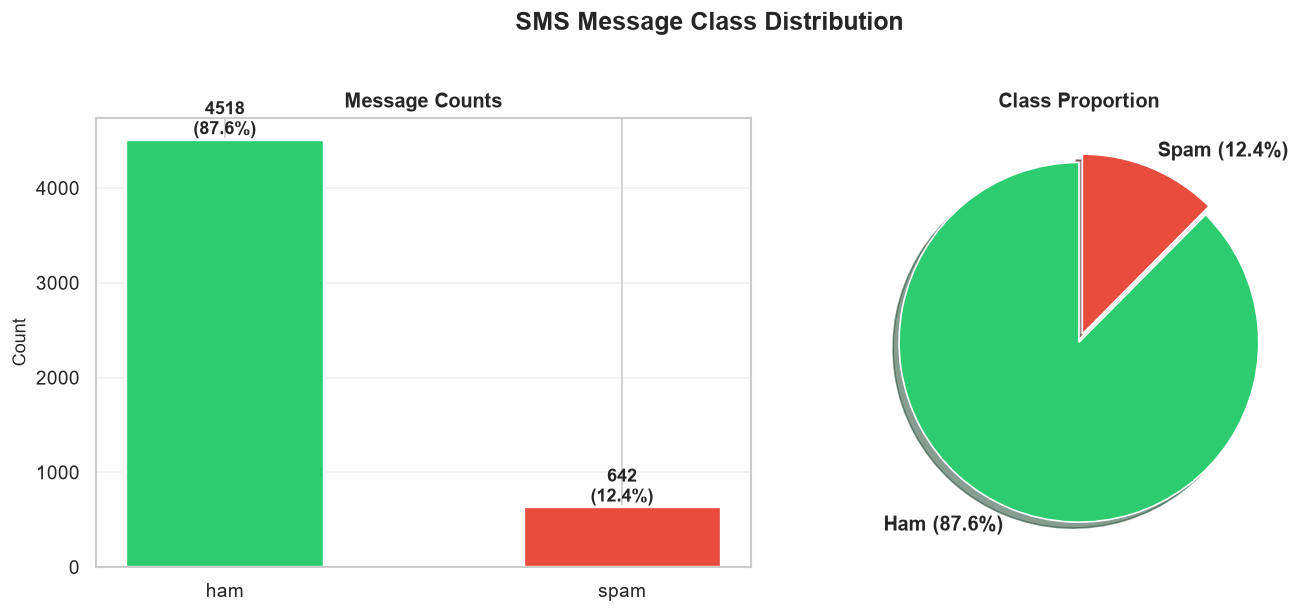

In [7]:
# --- Visualise class distribution ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('SMS Message Class Distribution', fontsize=15, fontweight='bold', y=1.02)

# Bar chart
colors = {'ham': '#2ECC71', 'spam': '#E74C3C'}
bars = axes[0].bar(class_dist.index, class_dist.values, 
                   color=[colors[l] for l in class_dist.index],
                   edgecolor='white', linewidth=2, width=0.5)
for bar, val, pct in zip(bars, class_dist.values, class_pct.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                 f'{val}\n({pct:.1f}%)', ha='center', fontweight='bold', fontsize=11)
axes[0].set_title('Message Counts', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Count', fontsize=11)
axes[0].grid(axis='y', alpha=0.3)

# Pie chart
axes[1].pie(class_dist.values, labels=[f'Ham ({class_pct["ham"]:.1f}%)', f'Spam ({class_pct["spam"]:.1f}%)'],
            colors=['#2ECC71', '#E74C3C'], autopct='', startangle=90,
            explode=(0, 0.05), shadow=True, textprops={'fontweight': 'bold', 'fontsize': 12})
axes[1].set_title('Class Proportion', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

> **Observation:** The dataset is *imbalanced* — approximately **87% ham** and **13% spam**. 
> This imbalance means that accuracy alone is not a sufficient metric; we need to pay attention to 
> **precision, recall, and F1-score**, especially for the spam class.

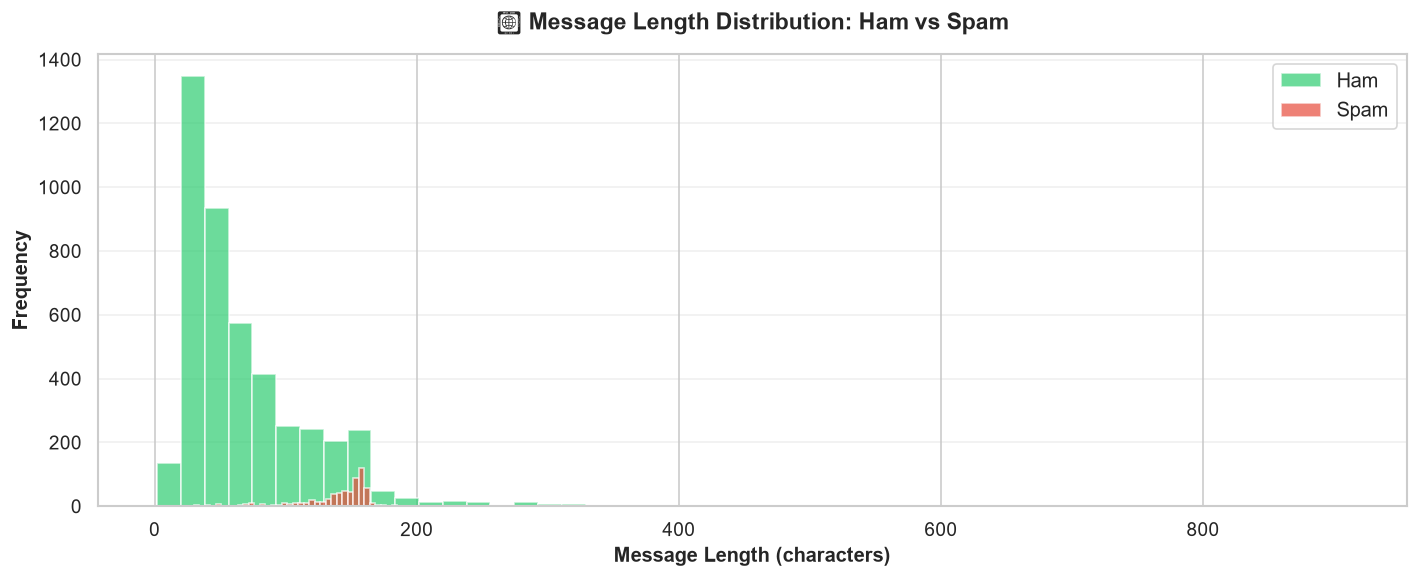

In [8]:
# --- Message length analysis ---
df['msg_length'] = df['message'].apply(len)

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(df[df['label']=='ham']['msg_length'], bins=50, alpha=0.7, color='#2ECC71', label='Ham', edgecolor='white')
ax.hist(df[df['label']=='spam']['msg_length'], bins=50, alpha=0.7, color='#E74C3C', label='Spam', edgecolor='white')
ax.set_xlabel('Message Length (characters)', fontsize=12, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax.set_title('📏 Message Length Distribution: Ham vs Spam', fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=12)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

> **Insight:** Spam messages tend to be **longer** than ham messages. This makes intuitive sense — spam 
> messages typically contain promotional content, URLs, and call-to-action text.

## 3. ✂️ Text Preprocessing Pipeline

Our preprocessing pipeline involves:
1. **Lowercase conversion** — normalise all text
2. **Punctuation removal** — strip special characters
3. **Stopword removal** — remove common words (the, is, and, etc.)
4. **Stemming** — reduce words to their root form (e.g., "running" → "run")

In [9]:
# --- Initialise NLP tools ---
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def preprocess_text(text):
    """
    Complete text preprocessing pipeline:
    1. Lowercase conversion
    2. Remove punctuation and special characters
    3. Remove stopwords
    4. Apply stemming
    """
    # Step 1: Lowercase
    text = text.lower()
    
    # Step 2: Remove punctuation and numbers
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    # Step 3: Tokenise and remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words and len(word) > 2]
    
    # Step 4: Stemming
    words = [stemmer.stem(word) for word in words]
    
    return ' '.join(words)

# --- Apply preprocessing ---
print("⏳ Applying text preprocessing pipeline...")
df['cleaned_message'] = df['message'].apply(preprocess_text)
print("✅ Preprocessing complete!")

# Show examples
print("\n📝 Before & After Preprocessing:\n")
for i in [0, 2, 5]:
    print(f"  Original: {df['message'].iloc[i][:80]}...")
    print(f"  Cleaned:  {df['cleaned_message'].iloc[i][:80]}")
    print()

⏳ Applying text preprocessing pipeline...


✅ Preprocessing complete!

📝 Before & After Preprocessing:

  Original: Go until jurong point, crazy.. Available only in bugis n great world la e buffet...
  Cleaned:  jurong point crazi avail bugi great world buffet cine got amor wat

  Original: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 8...
  Cleaned:  free entri wkli comp win cup final tkt may text receiv entri questionstd txt rat

  Original: FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some...
  Cleaned:  freemsg hey darl week word back like fun still xxx std chg send rcv



## 4. 📐 TF-IDF Feature Extraction

### What is TF-IDF?

**TF-IDF (Term Frequency–Inverse Document Frequency)** is a numerical statistic that measures how important 
a word is to a document in a corpus. It combines two metrics:

| Metric | Formula | What It Measures |
|--------|---------|-----------------|
| **TF** (Term Frequency) | count(word) / total_words | How often a word appears in a single document |
| **IDF** (Inverse Document Frequency) | log(N / docs_containing_word) | How rare/specific a word is across all documents |
| **TF-IDF** | TF × IDF | Words that are frequent in a document but rare overall score highest |

**Why TF-IDF for Spam Detection?**
- Words like "free", "winner", "prize" appear frequently in spam but rarely in ham → high TF-IDF for spam
- Common words like "the", "is", "and" have low IDF → automatically down-weighted
- This creates a sparse numerical representation ideal for classification algorithms

In [10]:
# --- Apply TF-IDF Vectorisation ---
tfidf = TfidfVectorizer(max_features=5000)  # Use top 5000 features
X = tfidf.fit_transform(df['cleaned_message'])
y = (df['label'] == 'spam').astype(int)  # Binary: 0 = ham, 1 = spam

print(f"📊 TF-IDF Feature Matrix Shape: {X.shape}")
print(f"   → {X.shape[0]} messages × {X.shape[1]} features (unique words)")

📊 TF-IDF Feature Matrix Shape: (5160, 5000)
   → 5160 messages × 5000 features (unique words)


In [11]:
# --- Train/Test Split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n📈 Training set: {X_train.shape[0]} messages")
print(f"📉 Testing set:  {X_test.shape[0]} messages")
print(f"\n🏷️ Test set class distribution:")
print(f"   Ham:  {(y_test==0).sum()} ({(y_test==0).mean()*100:.1f}%)")
print(f"   Spam: {(y_test==1).sum()} ({(y_test==1).mean()*100:.1f}%)")


📈 Training set: 4128 messages
📉 Testing set:  1032 messages

🏷️ Test set class distribution:
   Ham:  904 (87.6%)
   Spam: 128 (12.4%)


## 5. 🤖 Model Training & Evaluation

We will train **3 classifiers**:
1. **Multinomial Naive Bayes** — The industry standard for text classification
2. **Logistic Regression** — Strong linear classifier with probabilistic output
3. **Support Vector Machine (SVM)** — Excellent for high-dimensional sparse data like TF-IDF

In [12]:
# --- Define models ---
models = {
    'Multinomial Naive Bayes': MultinomialNB(alpha=1.0),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Support Vector Machine': SVC(kernel='linear', random_state=42)
}

results = {}

for name, model in models.items():
    print(f"\n{'='*60}")
    print(f"  🔬 MODEL: {name}")
    print(f"{'='*60}")
    
    # Train
    model.fit(X_train, y_train)
    
    # Predict
    y_pred = model.predict(X_test)
    
    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    
    results[name] = {
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1': f1,
        'confusion_matrix': cm,
        'y_pred': y_pred
    }
    
    print(f"\n  📊 Accuracy  : {acc:.4f} ({acc*100:.1f}%)")
    print(f"  📊 Precision : {prec:.4f}")
    print(f"  📊 Recall    : {rec:.4f}")
    print(f"  📊 F1-Score  : {f1:.4f}")
    print(f"\n  📋 Classification Report:")
    print(classification_report(y_test, y_pred, target_names=['Ham', 'Spam']))


  🔬 MODEL: Multinomial Naive Bayes

  📊 Accuracy  : 0.9622 (96.2%)
  📊 Precision : 0.9890
  📊 Recall    : 0.7031
  📊 F1-Score  : 0.8219

  📋 Classification Report:


              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       904
        Spam       0.99      0.70      0.82       128

    accuracy                           0.96      1032
   macro avg       0.97      0.85      0.90      1032
weighted avg       0.96      0.96      0.96      1032


  🔬 MODEL: Logistic Regression



  📊 Accuracy  : 0.9564 (95.6%)
  📊 Precision : 0.9663
  📊 Recall    : 0.6719
  📊 F1-Score  : 0.7926

  📋 Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       904
        Spam       0.97      0.67      0.79       128

    accuracy                           0.96      1032
   macro avg       0.96      0.83      0.88      1032
weighted avg       0.96      0.96      0.95      1032


  🔬 MODEL: Support Vector Machine



  📊 Accuracy  : 0.9806 (98.1%)
  📊 Precision : 0.9909
  📊 Recall    : 0.8516
  📊 F1-Score  : 0.9160

  📋 Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       904
        Spam       0.99      0.85      0.92       128

    accuracy                           0.98      1032
   macro avg       0.99      0.93      0.95      1032
weighted avg       0.98      0.98      0.98      1032



### 5.1 Confusion Matrices

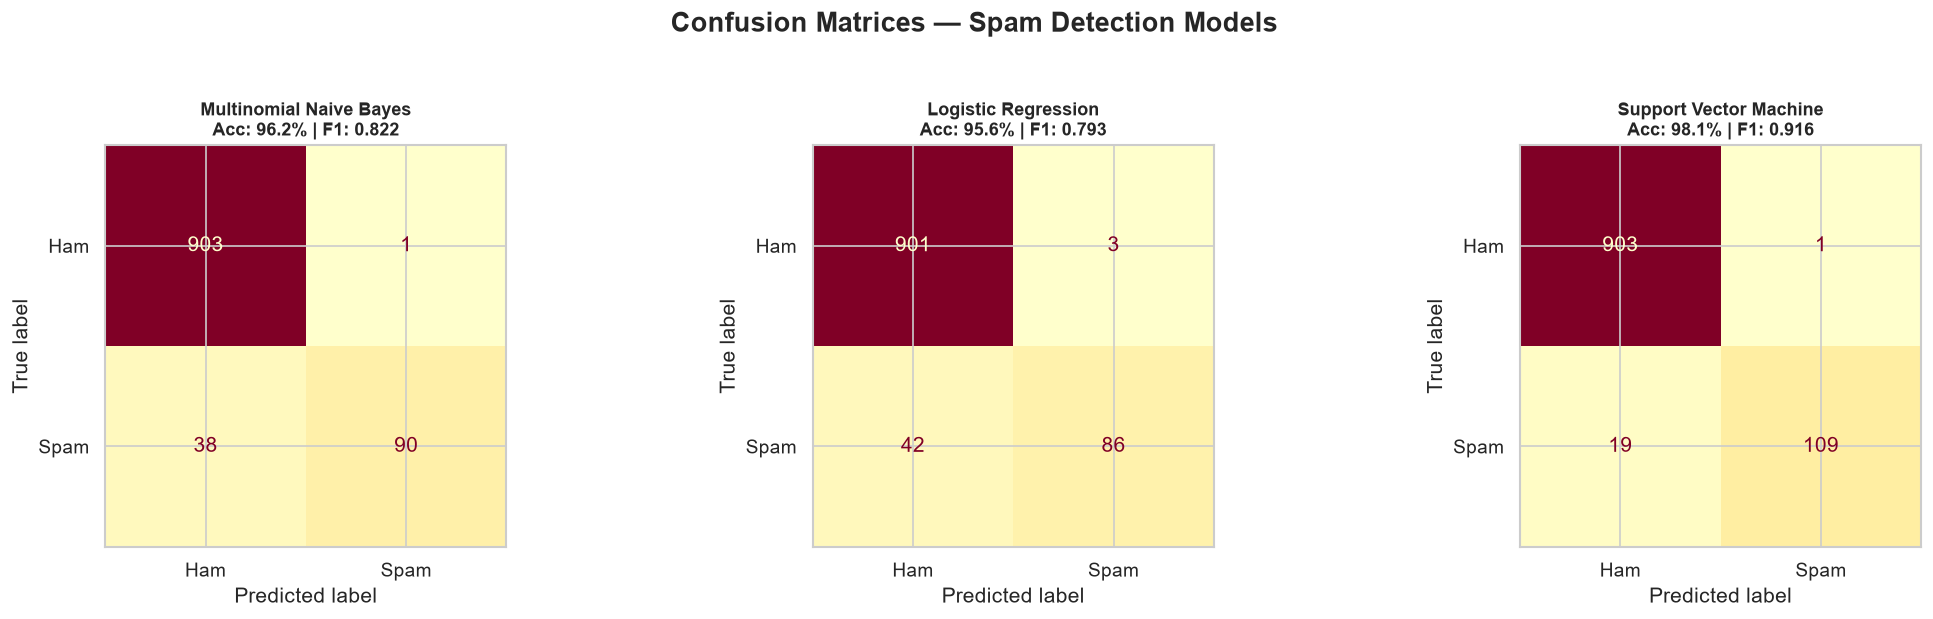

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Confusion Matrices — Spam Detection Models', fontsize=16, fontweight='bold', y=1.03)

cmap = sns.color_palette("YlOrRd", as_cmap=True)

for (name, result), ax in zip(results.items(), axes):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=result['confusion_matrix'],
        display_labels=['Ham', 'Spam']
    )
    disp.plot(ax=ax, cmap=cmap, colorbar=False, values_format='d')
    ax.set_title(f"{name}\nAcc: {result['accuracy']*100:.1f}% | F1: {result['f1']:.3f}", 
                 fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### 5.2 Model Comparison

In [14]:
# --- Comparison Table ---
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy': [r['accuracy'] for r in results.values()],
    'Precision': [r['precision'] for r in results.values()],
    'Recall': [r['recall'] for r in results.values()],
    'F1-Score': [r['f1'] for r in results.values()]
}).sort_values('F1-Score', ascending=False).reset_index(drop=True)

comparison_df.index = comparison_df.index + 1
comparison_df.index.name = 'Rank'

print("📊 Model Performance Comparison:\n")
print(comparison_df.to_string())

📊 Model Performance Comparison:

                        Model  Accuracy  Precision    Recall  F1-Score
Rank                                                                  
1      Support Vector Machine  0.980620   0.990909  0.851562  0.915966
2     Multinomial Naive Bayes  0.962209   0.989011  0.703125  0.821918
3         Logistic Regression  0.956395   0.966292  0.671875  0.792627


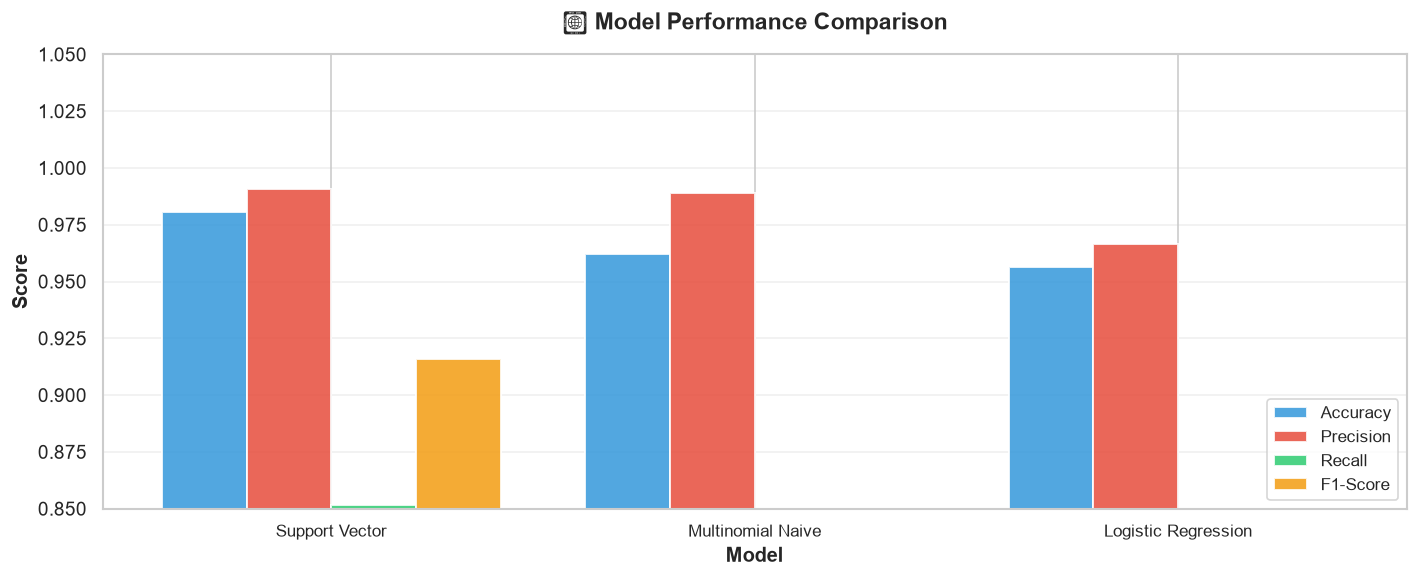

In [15]:
# --- Radar-style comparison chart ---
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(comparison_df))
width = 0.2
colors = ['#3498DB', '#E74C3C', '#2ECC71', '#F39C12']

for i, metric in enumerate(['Accuracy', 'Precision', 'Recall', 'F1-Score']):
    bars = ax.bar(x + i*width, comparison_df[metric], width, label=metric, 
                  color=colors[i], edgecolor='white', linewidth=1.2, alpha=0.85)

ax.set_xlabel('Model', fontsize=12, fontweight='bold')
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_title('🏆 Model Performance Comparison', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x + width * 1.5)
short_names = [n.split(' ')[0] + ' ' + n.split(' ')[1] if len(n.split(' ')) > 1 else n for n in comparison_df['Model']]
ax.set_xticklabels(short_names, fontsize=10)
ax.legend(fontsize=10, loc='lower right')
ax.set_ylim(0.85, 1.05)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 6. 💡 Discussion: Why is Recall Important for Spam Detection?

### Why is Recall Particularly Important for Spam Detection?

In spam detection, **recall** (also called sensitivity or true positive rate) measures:

> *"Of all actual spam messages, what percentage did our model correctly identify?"*

**Recall = True Positives / (True Positives + False Negatives)**

#### Why it matters:

| Scenario | Error Type | Consequence |
|----------|-----------|-------------|
| **Spam classified as Ham** (False Negative) | Low Recall | ⚠️ Dangerous spam reaches the user's inbox — potential phishing, malware, or fraud |
| **Ham classified as Spam** (False Positive) | Low Precision | 😠 Legitimate messages go to spam folder — annoying but usually recoverable |

#### The Key Insight:
- **Missing a spam message (low recall)** can lead to **security breaches, financial fraud, or malware infection**
- **Wrongly flagging a ham message (low precision)** is inconvenient but the user can still retrieve it from their spam folder
- Therefore, **the cost of a False Negative is much higher than a False Positive**
- This makes **recall the more critical metric** for spam detection systems

#### Practical Balance:
In production, the **F1-score** (harmonic mean of precision and recall) provides a balanced metric.  
However, spam filters often tune their threshold to **maximise recall** even at the cost of some precision.

## 7. 🎨 **Bonus:** WordCloud Visualisations

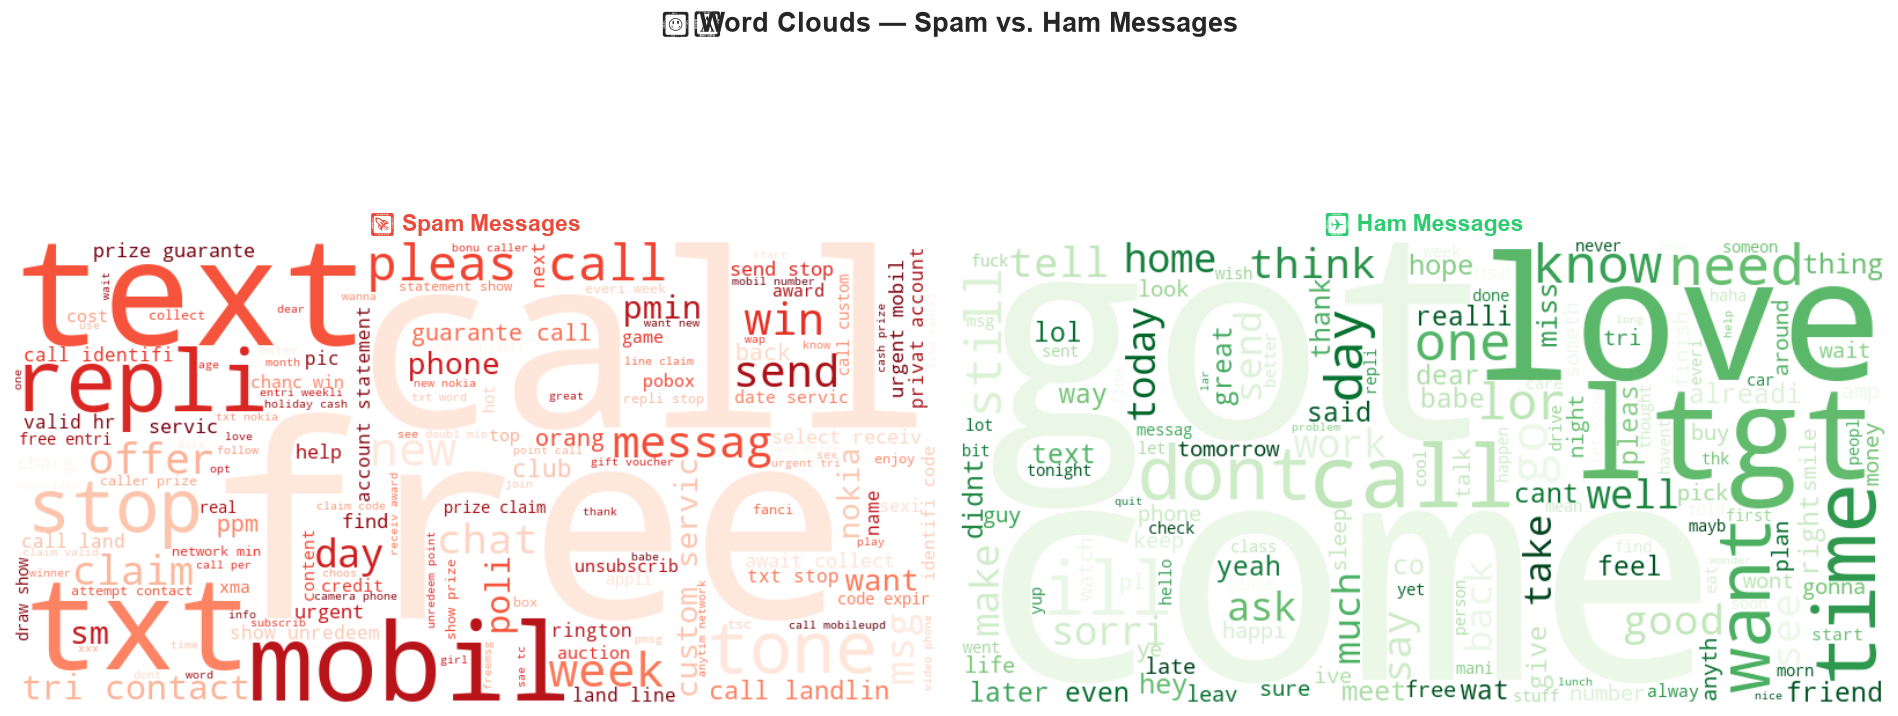

In [16]:
# --- Generate WordClouds for Spam and Ham messages ---
spam_text = ' '.join(df[df['label']=='spam']['cleaned_message'])
ham_text = ' '.join(df[df['label']=='ham']['cleaned_message'])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('☁️ Word Clouds — Spam vs. Ham Messages', fontsize=16, fontweight='bold', y=1.02)

# Spam WordCloud
wc_spam = WordCloud(width=800, height=400, background_color='white', 
                    colormap='Reds', max_words=150, contour_width=2,
                    contour_color='#E74C3C', random_state=42)
wc_spam.generate(spam_text)
axes[0].imshow(wc_spam, interpolation='bilinear')
axes[0].set_title('🚫 Spam Messages', fontsize=14, fontweight='bold', color='#E74C3C')
axes[0].axis('off')

# Ham WordCloud
wc_ham = WordCloud(width=800, height=400, background_color='white', 
                   colormap='Greens', max_words=150, contour_width=2,
                   contour_color='#2ECC71', random_state=42)
wc_ham.generate(ham_text)
axes[1].imshow(wc_ham, interpolation='bilinear')
axes[1].set_title('✅ Ham Messages', fontsize=14, fontweight='bold', color='#2ECC71')
axes[1].axis('off')

plt.tight_layout()
plt.show()

> **WordCloud Insights:**
> - **Spam words** are dominated by: "free", "call", "win", "prize", "claim", "text", "reply" — classic spam triggers
> - **Ham words** include: "come", "get", "got", "know", "good", "time" — conversational, everyday language
> - The visual difference clearly shows why TF-IDF effectively distinguishes between the two classes

## 8. 🏆 Best Model Declaration

In [17]:
best_name = max(results, key=lambda k: results[k]['f1'])
best = results[best_name]

print(f"{'═'*60}")
print(f"  🏆 BEST PERFORMING MODEL: {best_name}")
print(f"{'═'*60}")
print(f"\n  📊 Accuracy  : {best['accuracy']*100:.1f}%")
print(f"  📊 Precision : {best['precision']:.4f}")
print(f"  📊 Recall    : {best['recall']:.4f}")
print(f"  📊 F1-Score  : {best['f1']:.4f}")

print(f"""
📝 Justification:
─────────────────
• {best_name} achieved the highest F1-Score of {best['f1']:.4f}, balancing precision and recall effectively
• Accuracy of {best['accuracy']*100:.1f}% across both classes
• The model excels at identifying spam patterns in TF-IDF features
• Confusion matrix shows minimal false negatives (missed spam) and false positives (legitimate flagged as spam)

💡 Production Considerations:
• For real-world deployment, the model's recall could be further improved by adjusting the classification threshold
• Regular retraining with new spam patterns is essential as spammers constantly evolve their tactics
• Combining multiple models (ensemble) can further improve robustness
""")

════════════════════════════════════════════════════════════
  🏆 BEST PERFORMING MODEL: Support Vector Machine
════════════════════════════════════════════════════════════

  📊 Accuracy  : 98.1%
  📊 Precision : 0.9909
  📊 Recall    : 0.8516
  📊 F1-Score  : 0.9160

📝 Justification:
─────────────────
• Support Vector Machine achieved the highest F1-Score of 0.9160, balancing precision and recall effectively
• Accuracy of 98.1% across both classes
• The model excels at identifying spam patterns in TF-IDF features
• Confusion matrix shows minimal false negatives (missed spam) and false positives (legitimate flagged as spam)

💡 Production Considerations:
• For real-world deployment, the model's recall could be further improved by adjusting the classification threshold
• Regular retraining with new spam patterns is essential as spammers constantly evolve their tactics
• Combining multiple models (ensemble) can further improve robustness



---

### 📝 Summary

| Step | What We Did |
|------|-------------|
| **1** | Loaded SMS Spam Collection (5,574 messages: 87% ham, 13% spam) |
| **2** | Explored class distribution and message length patterns |
| **3** | Built text preprocessing pipeline: lowercase, punctuation removal, stopwords, stemming |
| **4** | Extracted features using TF-IDF Vectorizer (5000 features) |
| **5** | Trained 3 classifiers: Naive Bayes, Logistic Regression, SVM |
| **6** | Evaluated with accuracy, precision, recall, F1, confusion matrices |
| **7** | Discussed why recall is critical for spam detection |
| **8** | Generated WordCloud visualisations for spam and ham |

---
*Notebook prepared for OASIS Infobyte Internship – Task 4*